In [ ]:
#!pip install lime -q
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from lime.lime_tabular import LimeTabularExplainer

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)
print("Libraries loaded.")

PyTorch version: 2.11.0+cpu
Libraries loaded.


In [ ]:
!pip install lime -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
data = load_breast_cancer()

feature_names = [str(n) for n in data.feature_names]
class_names   = [str(n) for n in data.target_names]    # ['malignant', 'benign']

df = pd.DataFrame(data.data, columns=feature_names)
df["target"]    = data.target
df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})

print("Rows (patients)  :", df.shape[0])
print("Feature columns  :", len(feature_names))
print("Class names      :", class_names, "-> label 0 and label 1")
print("First 6 features :", feature_names[:6])

Rows (patients)  : 569
Feature columns  : 30
Class names      : ['malignant', 'benign'] -> label 0 and label 1
First 6 features : ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness']


In [ ]:
df[feature_names[:6] + ["diagnosis"]].head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,malignant


In [ ]:
print("Total missing values:", int(df[feature_names].isna().sum().sum()))
print("Data types of features:", df[feature_names].dtypes.unique())

Total missing values: 0
Data types of features: [dtype('float64')]


diagnosis
benign       357
malignant    212
Name: count, dtype: int64

diagnosis
benign       62.7 %
malignant    37.3 %
Name: count, dtype: object


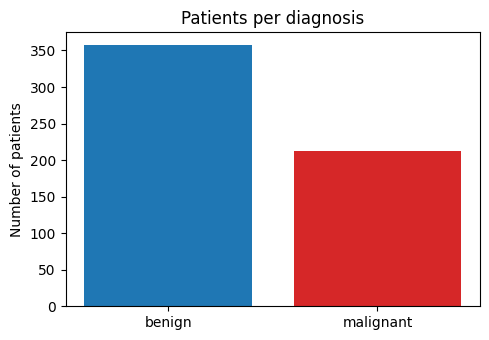

In [ ]:
counts = df["diagnosis"].value_counts()
print(counts)
print()
print((counts / len(df) * 100).round(1).astype(str) + " %")

plt.figure(figsize=(5, 3.5))
plt.bar(counts.index, counts.values, color=["tab:blue", "tab:red"])
plt.ylabel("Number of patients")
plt.title("Patients per diagnosis")
plt.tight_layout()
plt.show()

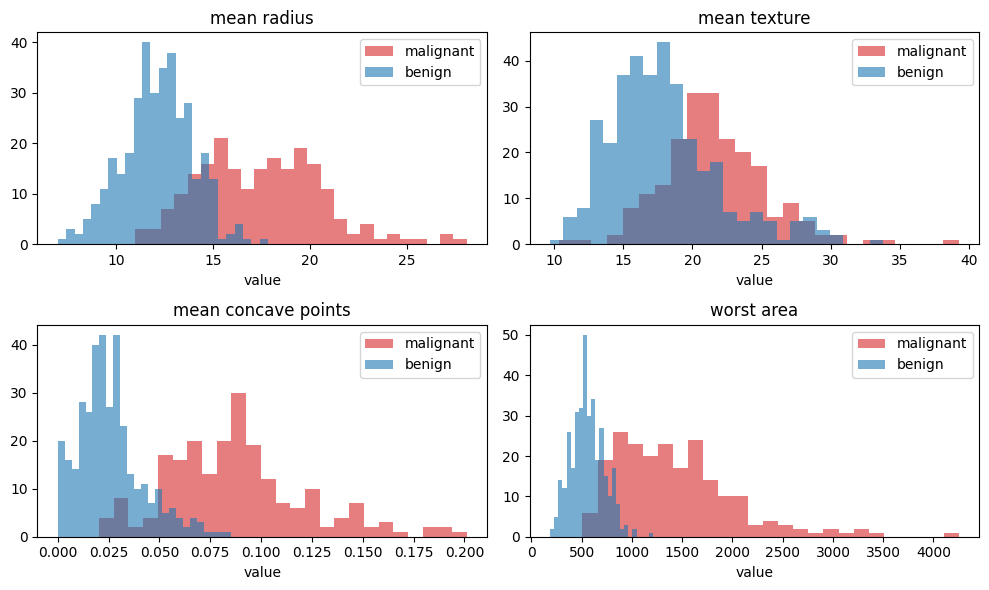

In [ ]:
features_to_plot = ["mean radius", "mean texture", "mean concave points", "worst area"]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, feat in zip(axes.flat, features_to_plot):
    for name, color in [("malignant", "tab:red"), ("benign", "tab:blue")]:
        ax.hist(df.loc[df["diagnosis"] == name, feat], bins=25, alpha=0.6, label=name, color=color)
    ax.set_title(feat)
    ax.set_xlabel("value")
    ax.legend()

plt.tight_layout()
plt.show()


In [ ]:
X = data.data          # raw numbers, shape (569, 30)
y = data.target        # 0 = malignant, 1 = benign

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

scaler = StandardScaler().fit(X_train)        # learn mean/std from training data only
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Malignant share in train:", round((y_train == 0).mean() * 100, 1), "%")
print("Malignant share in test :", round((y_test == 0).mean() * 100, 1), "%")
print()
print("Before scaling, 'mean area' in train: mean =", round(X_train[:, 3].mean(), 1), ", std =", round(X_train[:, 3].std(), 1))
print("After scaling,  'mean area' in train: mean =", round(X_train_s[:, 3].mean(), 3), ", std =", round(X_train_s[:, 3].std(), 3))

Train shape: (455, 30) | Test shape: (114, 30)
Malignant share in train: 37.4 %
Malignant share in test : 36.8 %

Before scaling, 'mean area' in train: mean = 648.5 , std = 344.6
After scaling,  'mean area' in train: mean = 0.0 , std = 1.0


In [ ]:
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train,   dtype=torch.long)
X_test_t  = torch.tensor(X_test_s,  dtype=torch.float32)
y_test_t  = torch.tensor(y_test,    dtype=torch.long)

train_ds     = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)

xb, yb = next(iter(train_loader))
print("One batch of features:", tuple(xb.shape), "-> (batch, features)")
print("One batch of labels  :", tuple(yb.shape))
print("Batches per epoch    :", len(train_loader))

One batch of features: (32, 30) -> (batch, features)
One batch of labels  : (32,)
Batches per epoch    : 15


In [ ]:
class TabularNet(nn.Module):
    def __init__(self, n_features, n_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, n_classes),     # raw scores (logits), one per class
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
model = TabularNet(n_features=30)
print(model)

n_params = sum(p.numel() for p in model.parameters())
print("\nTotal trainable parameters:", f"{n_params:,}")

with torch.no_grad():
    print("Output shape for one batch:", tuple(model(xb).shape), "-> (batch, 2 class scores)")

TabularNet(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=2, bias=True)
  )
)

Total trainable parameters: 1,554
Output shape for one batch: (32, 2) -> (batch, 2 class scores)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 40
history = {"loss": [], "acc": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, correct = 0.0, 0

    for xb, yb in train_loader:
        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)
        correct      += (outputs.argmax(dim=1) == yb).sum().item()

    epoch_loss = running_loss / len(train_ds)
    epoch_acc  = correct / len(train_ds) * 100
    history["loss"].append(epoch_loss)
    history["acc"].append(epoch_acc)

    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch:>2}/{EPOCHS} | loss: {epoch_loss:.4f} | train accuracy: {epoch_acc:.2f}%")

Epoch  1/40 | loss: 0.6333 | train accuracy: 74.07%
Epoch  5/40 | loss: 0.1952 | train accuracy: 95.82%
Epoch 10/40 | loss: 0.0693 | train accuracy: 98.46%
Epoch 15/40 | loss: 0.0487 | train accuracy: 98.90%
Epoch 20/40 | loss: 0.0391 | train accuracy: 99.12%
Epoch 25/40 | loss: 0.0322 | train accuracy: 99.12%
Epoch 30/40 | loss: 0.0268 | train accuracy: 99.12%
Epoch 35/40 | loss: 0.0223 | train accuracy: 99.34%
Epoch 40/40 | loss: 0.0175 | train accuracy: 99.56%


In [ ]:
model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_probs  = torch.softmax(test_logits, dim=1).numpy()    # shape (114, 2)

test_pred = test_probs.argmax(axis=1)
test_acc  = (test_pred == y_test).mean() * 100

print(f"Test accuracy: {test_acc:.2f}%  ({(test_pred != y_test).sum()} mistakes out of {len(y_test)})")
print("\nConfusion matrix (rows = true class, columns = predicted class):")
print(pd.DataFrame(confusion_matrix(y_test, test_pred),
                   index=[f"true {c}" for c in class_names],
                   columns=[f"pred {c}" for c in class_names]))
print("\n", classification_report(y_test, test_pred, target_names=class_names))

Test accuracy: 96.49%  (4 mistakes out of 114)

Confusion matrix (rows = true class, columns = predicted class):
                pred malignant  pred benign
true malignant              41            1
true benign                  3           69

               precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



In [ ]:
def predict_proba(x_raw):
    """x_raw: numpy array (N, 30) in ORIGINAL units  ->  numpy array (N, 2) of probabilities."""
    x_scaled = scaler.transform(x_raw)
    x_tensor = torch.tensor(x_scaled, dtype=torch.float32)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x_tensor), dim=1)
    return probs.numpy()


In [ ]:
# 2 patients I am picking up. 1 patient classifoed correctly as malignant
#and another classified correctly as benign

In [ ]:
idx_malignant = np.where((y_test == 0) & (test_pred == 0))[0][0]
idx_benign    = np.where((y_test == 1) & (test_pred == 1))[0][0]

for name, idx in [("Malignant patient", idx_malignant), ("Benign patient", idx_benign)]:
    p = test_probs[idx]
    print(f"{name}: test row #{idx} | P(malignant) = {p[0]:.3f} | P(benign) = {p[1]:.3f}")

Malignant patient: test row #0 | P(malignant) = 1.000 | P(benign) = 0.000
Benign patient: test row #1 | P(malignant) = 0.000 | P(benign) = 1.000


In [ ]:
rng = np.random.default_rng(0)
instance = X_test[idx_malignant]
n_features = len(feature_names)

rows = [instance]
for _ in range(5):
    keep = rng.random(n_features) < 0.5                                   # keep ~half of the features
    random_values = X_train[rng.integers(0, len(X_train), size=n_features), np.arange(n_features)]
    rows.append(np.where(keep, instance, random_values))                  # replace the rest
rows = np.array(rows)

show_cols = ["mean radius", "mean texture", "mean concave points", "worst perimeter", "worst area"]
col_idx = [feature_names.index(c) for c in show_cols]

peek = pd.DataFrame(rows[:, col_idx], columns=show_cols,
                    index=["original", "fake 1", "fake 2", "fake 3", "fake 4", "fake 5"]).round(2)
peek["P(malignant)"] = predict_proba(rows)[:, 0].round(3)
peek

,mean radius,mean texture,mean concave points,worst perimeter,worst area,P(malignant)
original,19.55,28.77,0.11,178.60,1926.0,1.000
fake 1,10.48,28.77,0.07,70.10,574.4,1.000
fake 2,11.41,28.77,0.09,83.74,1926.0,1.000
fake 3,20.13,15.04,0.05,90.14,1926.0,1.000
fake 4,19.55,22.15,0.01,178.60,240.1,0.975
fake 5,17.93,28.77,0.01,129.30,1926.0,1.000


In [ ]:
explainer = LimeTabularExplainer(training_data=X_train,feature_names=feature_names,
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    random_state=SEED,
)

exp_m = explainer.explain_instance(
    data_row=X_test[idx_malignant],
    predict_fn=predict_proba,
    num_features=8,
    top_labels=1,
    num_samples=5000,
)

label_m = exp_m.top_labels[0]
print("Class being explained:", class_names[label_m])
print("Model probabilities  :", {c: round(float(v), 3) for c, v in zip(class_names, exp_m.predict_proba)})

score = exp_m.score[label_m] if isinstance(exp_m.score, dict) else exp_m.score
print(f"Local model R^2 (how well the simple model mimics the network here): {score:.3f}")

Class being explained: malignant
Model probabilities  : {'malignant': 1.0, 'benign': 0.0}
Local model R^2 (how well the simple model mimics the network here): 0.302


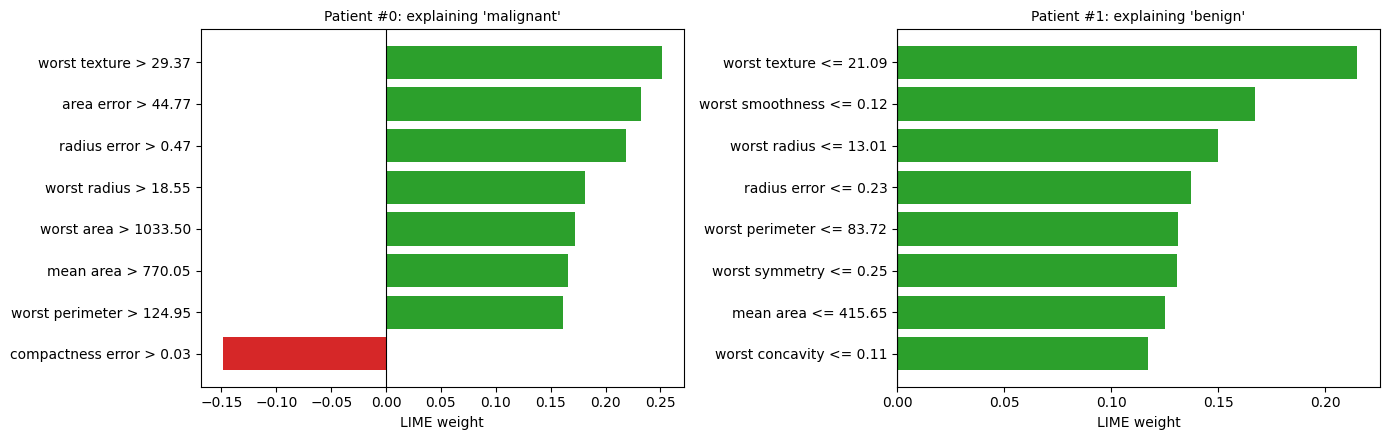

In [ ]:
exp_b = explainer.explain_instance(
    data_row=X_test[idx_benign],
    predict_fn=predict_proba,
    num_features=8,
    top_labels=1,
    num_samples=5000,
)
label_b = exp_b.top_labels[0]


def plot_explanation(exp, label, ax, title):
    items = exp.as_list(label=label)[::-1]          # reverse so the biggest bar is at the top
    names = [n for n, _ in items]
    weights = [w for _, w in items]
    colors = ["tab:green" if w > 0 else "tab:red" for w in weights]
    ax.barh(names, weights, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("LIME weight")


fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_explanation(exp_m, label_m, axes[0], f"Patient #{idx_malignant}: explaining '{class_names[label_m]}'")
plot_explanation(exp_b, label_b, axes[1], f"Patient #{idx_benign}: explaining '{class_names[label_b]}'")
plt.tight_layout()
plt.show()